In [2]:
import pandas as pd
import json
from pathlib import Path

In [3]:
PROJECT_ROOT = Path.cwd().parent

PLAYERS_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "players_2025_26.csv"
)

STATS_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "player_statistics_2025_26.json"
)

In [4]:
players = pd.read_csv(PLAYERS_FILE)

with open(
    STATS_FILE,
    "r",
    encoding="utf-8"
) as file:
    stats_raw = json.load(file)

print("Players:", players.shape)
print("Statistics:", len(stats_raw))

Players: (574, 12)
Statistics: 574


In [5]:
players.head()

,player_id,name,team_id,team_name,birth_date,age_2025_26,is_u23,detailed_position,height_cm,preferred_foot,country,market_value_eur
0,1961855,João Afonso,3011,Santa Clara,2007-04-30 00:00:00+00:00,18.0,True,GK,187.0,Right,Portugal,1400000.0
1,1001196,Gonçalo Inácio,3001,Sporting CP,2001-08-25 00:00:00+00:00,23.0,False,DC,186.0,Left,Portugal,42000000.0
2,983550,Samuel Soares,3006,Benfica,2002-06-15 00:00:00+00:00,23.0,False,GK,189.0,Right,Portugal,3100000.0
3,1961117,José Neto,3006,Benfica,2008-04-19 00:00:00+00:00,17.0,True,DL,184.0,Left,Portugal,2700000.0
4,914213,Luis Javier Suárez,3001,Sporting CP,1997-12-02 00:00:00+00:00,27.0,False,ST,185.0,Right,Colombia,27000000.0


In [6]:
players.info()

<class 'pandas.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   player_id          574 non-null    int64  
 1   name               574 non-null    str    
 2   team_id            574 non-null    int64  
 3   team_name          574 non-null    str    
 4   birth_date         573 non-null    str    
 5   age_2025_26        573 non-null    float64
 6   is_u23             573 non-null    object 
 7   detailed_position  561 non-null    str    
 8   height_cm          571 non-null    float64
 9   preferred_foot     573 non-null    str    
 10  country            573 non-null    str    
 11  market_value_eur   560 non-null    float64
dtypes: float64(3), int64(2), object(1), str(6)
memory usage: 53.9+ KB


In [7]:
players.isna().sum()

player_id             0
name                  0
team_id               0
team_name             0
birth_date            1
age_2025_26           1
is_u23                1
detailed_position    13
height_cm             3
preferred_foot        1
country               1
market_value_eur     14
dtype: int64

In [8]:
players["birth_date"] = pd.to_datetime(
    players["birth_date"],
    errors="coerce",
    utc=True
)

players["is_u23"] = players["is_u23"].astype("boolean")

In [9]:
players.dtypes

player_id                          int64
name                                 str
team_id                            int64
team_name                            str
birth_date           datetime64[us, UTC]
age_2025_26                      float64
is_u23                           boolean
detailed_position                    str
height_cm                        float64
preferred_foot                       str
country                              str
market_value_eur                 float64
dtype: object

In [10]:
players["age_2025_26"].describe()

count    573.000000
mean      24.150087
std        4.303010
min       16.000000
25%       21.000000
50%       24.000000
75%       26.000000
max       41.000000
Name: age_2025_26, dtype: float64

In [11]:
players["age_2025_26"].value_counts().sort_index()

age_2025_26
16.0     1
17.0    12
18.0    13
19.0    37
20.0    48
21.0    52
22.0    62
23.0    59
24.0    62
25.0    53
26.0    43
27.0    30
28.0    21
29.0    16
30.0    17
31.0     9
32.0     7
33.0     4
34.0     8
35.0     8
36.0     3
37.0     2
38.0     3
40.0     1
41.0     2
Name: count, dtype: int64

In [12]:
players["is_u23"].value_counts(dropna=False)

is_u23
False    348
True     225
<NA>       1
Name: count, dtype: Int64

In [13]:
players["detailed_position"].value_counts(
    dropna=False
)

detailed_position
MC     118
DC      92
ST      79
LW      50
GK      44
DL      43
RW      43
DR      42
AM      21
ML      14
NaN     13
DM       8
MR       7
Name: count, dtype: int64

In [14]:
minutes = []

for item in stats_raw:

    stats = item["data"]["statistics"]

    minutes.append({
        "player_id": item["player_id"],
        "minutes_played": stats.get("minutesPlayed")
    })

minutes_df = pd.DataFrame(minutes)

minutes_df.head()

,player_id,minutes_played
0,1961855,180
1,1001196,2506
2,983550,180
3,1961117,94
4,914213,2698


In [15]:
minutes_df["minutes_played"].describe()

count     574.000000
mean     1058.770035
std       876.549926
min         1.000000
25%       256.750000
50%       885.500000
75%      1672.750000
max      3060.000000
Name: minutes_played, dtype: float64

In [16]:
minutes_df["minutes_played"].quantile(
    [0, 0.10, 0.25, 0.50, 0.75, 0.90, 1]
)

0.00       1.00
0.10      44.30
0.25     256.75
0.50     885.50
0.75    1672.75
0.90    2467.40
1.00    3060.00
Name: minutes_played, dtype: float64

In [17]:
minutes_df["minutes_played"].describe()

count     574.000000
mean     1058.770035
std       876.549926
min         1.000000
25%       256.750000
50%       885.500000
75%      1672.750000
max      3060.000000
Name: minutes_played, dtype: float64

In [18]:
minutes_df["minutes_played"].quantile(
    [0, 0.10, 0.25, 0.50, 0.75, 0.90, 1]
)

0.00       1.00
0.10      44.30
0.25     256.75
0.50     885.50
0.75    1672.75
0.90    2467.40
1.00    3060.00
Name: minutes_played, dtype: float64

In [19]:
players["is_u23"].value_counts(dropna=False)

is_u23
False    348
True     225
<NA>       1
Name: count, dtype: Int64

In [20]:
players["detailed_position"].value_counts(dropna=False)

detailed_position
MC     118
DC      92
ST      79
LW      50
GK      44
DL      43
RW      43
DR      42
AM      21
ML      14
NaN     13
DM       8
MR       7
Name: count, dtype: int64

In [21]:
minutes_df["minutes_played"].describe()

count     574.000000
mean     1058.770035
std       876.549926
min         1.000000
25%       256.750000
50%       885.500000
75%      1672.750000
max      3060.000000
Name: minutes_played, dtype: float64

In [22]:
minutes_df["minutes_played"].quantile(
    [0, 0.10, 0.25, 0.50, 0.75, 0.90, 1]
)

0.00       1.00
0.10      44.30
0.25     256.75
0.50     885.50
0.75    1672.75
0.90    2467.40
1.00    3060.00
Name: minutes_played, dtype: float64

## 4. Distribuição de minutos dos jogadores U23

Como o objetivo do projeto é scouting de jovens jogadores, analisamos
separadamente a distribuição de minutos dos atletas classificados como U23.

In [23]:
u23_ids = players.loc[
    players["is_u23"] == True,
    "player_id"
]

minutes_u23 = minutes_df[
    minutes_df["player_id"].isin(u23_ids)
]

print("Jogadores U23:", len(minutes_u23))

Jogadores U23: 225


In [24]:
minutes_u23["minutes_played"].describe()

count     225.000000
mean      801.208889
std       784.012975
min         1.000000
25%        94.000000
50%       589.000000
75%      1320.000000
max      3060.000000
Name: minutes_played, dtype: float64

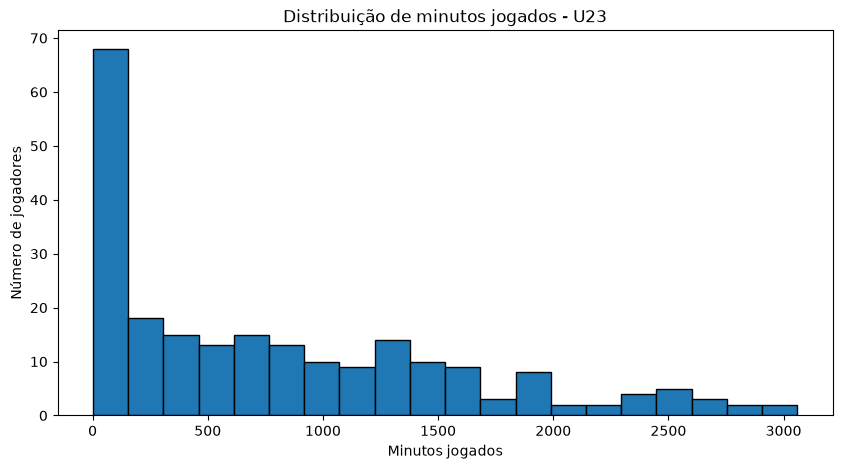

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    minutes_u23["minutes_played"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Minutos jogados")
plt.ylabel("Número de jogadores")
plt.title("Distribuição de minutos jogados - U23")

plt.show()

In [26]:
thresholds = [90, 180, 270, 450, 600, 900]

for threshold in thresholds:

    count = (
        minutes_u23["minutes_played"]
        >= threshold
    ).sum()

    percentage = (
        count / len(minutes_u23)
    ) * 100

    print(
        f"{threshold:>3} minutos: "
        f"{count:>3} jogadores "
        f"({percentage:.1f}%)"
    )

 90 minutos: 173 jogadores (76.9%)
180 minutos: 153 jogadores (68.0%)
270 minutos: 144 jogadores (64.0%)
450 minutos: 125 jogadores (55.6%)
600 minutos: 111 jogadores (49.3%)
900 minutos:  84 jogadores (37.3%)


## 5. Critério mínimo de minutos

A distribuição de minutos dos jogadores U23 apresenta forte concentração
de atletas com baixa exposição em campo.

Para reduzir a instabilidade das métricas normalizadas por 90 minutos,
foi adotado inicialmente um mínimo de **450 minutos (5 partidas completas)**
para inclusão nas comparações estatísticas.

Dos 225 jogadores U23:

- 125 jogadores (55,6%) possuem pelo menos 450 minutos;
- 100 jogadores possuem menos de 450 minutos.
